# 10 · Effective dimension and Fisher spectrum (Part D)

**No patient data is used.** This notebook measures the *capacity* of each trained model family with the
Fisher-information **effective dimension** of Abbas et al. (*Nature Computational Science* 1, 403–409, 2021),
and compares every VQC with classical models of matched size:

| Model | What it is |
|---|---|
| VQC | the modality circuit + its linear readout head + softmax — the full trainable model, same parameter count as the report |
| VQC, no entangling gates | the same circuit with every CNOT / CZ / ZZ gate removed (not for methylation, which has none) |
| MLP (matched) | one hidden tanh layer, hidden size chosen so the parameter count is as close as possible to the VQC's |
| LR | multinomial logistic regression on the same inputs (the classical baseline of the report) |

**How to read it.** The normalised effective dimension $d_\mathrm{eff}/d \in [0,1]$ says what fraction of a model's
$d$ parameters actually change its predictions, averaged over the whole parameter space; the Fisher eigenvalue
spectrum says whether that capacity is spread evenly (many similar eigenvalues) or concentrated in a few directions
(most eigenvalues ≈ 0, as is typical for classical networks). It is a *capacity* measure: a higher value is **not**
evidence that a model classifies better, and these small circuits remain easy to simulate classically. Report it as a
description of the models, next to the F1-scores of Parts A and C.

At small $n$ the normalised value can exceed the share of non-zero Fisher eigenvalues (the formula is a large-$n$
approximation), so quote the $n = 10^6$ column, as Abbas et al. do; every model with a softmax over 4 classes has
at least 1/4 of its head parameters in "null" directions (adding the same constant to all 4 logits changes nothing).

Inputs are drawn from each circuit's real input range (same samplers as Part B); classical models get the same
inputs, standardised. Runtime ≈ 15–25 min on a Kaggle CPU, mostly SNV (11 qubits); `FAST = True` → ≈ 4 min.

In [1]:
# ============================================================
# 0. SETTINGS
# ============================================================
import os, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

FAST = False                     # True = fewer samples, for a quick first run
SEED = 42
K = 4                            # classes
N_THETA = 30 if FAST else 100    # parameter draws (Abbas et al. use 100)
N_X = 40 if FAST else 100        # inputs per draw (Abbas et al. use 100)
N_SNV_THETA = 15 if FAST else 50 # SNV is 11 qubits: fewer draws keeps it to ~10 min
N_GRID = np.unique(np.logspace(2, 6, 30).astype(int))     # data sizes n for the curves
N_REPORT = [300, 1000, 10 ** 6]  # n values in the table (300 ~ the training set of one modality)
OUTPUT_DIR = os.path.join(os.environ.get("OUTPUT_DIR", "/kaggle/working" if os.path.isdir("/kaggle/working") else "."), "partD")
os.makedirs(OUTPUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

# ---- gene-expression circuit: the 9-qubit model of the shared-split run (03_gene_expression_shared_split) ----
# Graph printed by the edge cell of that notebook (12 edges, |r| >= 0.30, density 0.33).
GE_GENES = ["EIF3CL", "PABPC4", "FSTL5", "SCP2", "FAHD1", "BLACAT1", "VSTM2A", "CLVS1", "INPP5D"]   # qubit order
GE_EDGES = [(1, 3), (6, 7), (5, 6), (5, 7), (3, 8), (2, 6), (1, 8), (5, 8), (6, 8), (0, 2), (7, 8), (4, 5)]
GE_R = [0.71, 0.63, 0.56, 0.54, 0.51, 0.51, 0.47, -0.46, -0.46, -0.43, -0.37, 0.36]
assert GE_EDGES is not None and GE_R is not None and len(GE_EDGES) == len(GE_R), \
    "Paste GE_EDGES and GE_R from the edge printout of the shared-split gene notebook (see the instructions)."
print(f"Gene-expression circuit: {len(GE_GENES)} qubits, {len(GE_EDGES)} graph edges")

Gene-expression circuit: 9 qubits, 12 graph edges


In [2]:
# ============================================================
# 1. A SMALL EXACT STATEVECTOR SIMULATOR + THE SIX MODALITY CIRCUITS (AND THE META-VQC)
# Each circuit is a list of gates; every gate angle is a function of the input batch X and the parameter batch T,
# so the same description is used for expressibility, entanglement, gradients, noise and the Qiskit export.
# Conventions: RY(a) = exp(-i a Y/2), RZ(a) = exp(-i a Z/2), RZZ(a) = IsingZZ(a) = exp(-i a ZZ/2), Rot(p,t,w) = RZ(w) RY(t) RZ(p).
# ============================================================
import numpy as np

ENTANGLING = {"cnot", "cz", "rzz"}


class Circuit:
    def __init__(self, name, n, gates, n_params, sample_x, readout, head_obs, grad_param=0, layers=1, note=""):
        self.name, self.n, self.gates, self.n_params = name, n, gates, n_params
        self.sample_x, self.readout, self.head_obs = sample_x, readout, head_obs
        self.grad_param, self.layers, self.note = grad_param, layers, note

    def without_entanglers(self):
        return Circuit(self.name + " (no entangling gates)", self.n, [g for g in self.gates if g[0] not in ENTANGLING],
                       self.n_params, self.sample_x, self.readout, self.head_obs, self.grad_param, self.layers)

    def sample_params(self, B, rng):
        return rng.uniform(0, 2 * np.pi, (B, self.n_params))

    def rotation_params(self):
        # parameters that are plain rotation angles (the parameter-shift rule applies to them)
        return sorted({g[2].k for g in self.gates if g[2] is not None and hasattr(g[2], "k")})

    def probe_params(self, m=6):
        r = self.rotation_params()
        return [r[i] for i in np.unique(np.linspace(0, len(r) - 1, min(m, len(r))).round().astype(int))]

    # ---- simulation --------------------------------------------------------
    def states(self, X, T):
        B, n = len(X), self.n
        psi = np.zeros((B, 2 ** n), complex); psi[:, 0] = 1.0
        for g in self.gates:
            psi = apply_gate(psi, n, g, X, T)
        return psi

    def expvals(self, psi):
        p = np.abs(psi) ** 2
        return np.stack([p @ zsign(self.n, obs) for obs in self.readout], 1)

    # ---- static resources --------------------------------------------------
    def counts(self):
        one = sum(1 for g in self.gates if len(g[1]) == 1)
        two = sum(1 for g in self.gates if len(g[1]) == 2)
        by = {}
        for g in self.gates:
            by[g[0]] = by.get(g[0], 0) + 1
        return one, two, by

    def depth(self):
        lvl = [0] * self.n
        for g in self.gates:
            d = max(lvl[q] for q in g[1]) + 1
            for q in g[1]:
                lvl[q] = d
        return max(lvl)


_ZS = {}


def zsign(n, qubits):
    key = (n, tuple(qubits))
    if key not in _ZS:
        idx = np.arange(2 ** n); s = np.ones(2 ** n)
        for q in qubits:
            s *= 1 - 2 * ((idx >> (n - 1 - q)) & 1)
        _ZS[key] = s
    return _ZS[key]


def apply_gate(psi, n, g, X, T):
    kind, wires, ang = g[0], g[1], g[2]
    B = psi.shape[0]
    if kind in ("ry", "rz"):
        a = ang(X, T); q = wires[0]
        v = psi.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))
        if kind == "ry":
            c, s = np.cos(a / 2)[:, None, None], np.sin(a / 2)[:, None, None]
            a0, a1 = v[:, :, 0, :], v[:, :, 1, :]
            out = np.empty_like(v); out[:, :, 0, :] = c * a0 - s * a1; out[:, :, 1, :] = s * a0 + c * a1
            return out.reshape(B, -1)
        e = np.exp(-0.5j * a)[:, None]
        return psi * np.where(zsign(n, (q,))[None, :] > 0, e, np.conj(e))
    if kind == "rzz":
        a = ang(X, T)
        return psi * np.exp(-0.5j * a[:, None] * zsign(n, wires)[None, :])
    if kind == "cz":
        return psi * zsign_cz(n, wires)[None, :]
    if kind == "cnot":
        c, t = wires
        v = psi.reshape((B,) + (2,) * n).copy()
        sl = [slice(None)] * (n + 1); sl[c + 1] = 1
        sub = v[tuple(sl)]
        ax = t + 1 if t < c else t
        v[tuple(sl)] = np.flip(sub, axis=ax)
        return v.reshape(B, -1)
    raise ValueError(kind)


_CZ = {}


def zsign_cz(n, wires):
    key = (n, tuple(wires))
    if key not in _CZ:
        idx = np.arange(2 ** n); a, b = wires
        _CZ[key] = np.where(((idx >> (n - 1 - a)) & 1) & ((idx >> (n - 1 - b)) & 1), -1.0, 1.0)
    return _CZ[key]


# ---- angle helpers ---------------------------------------------------------
xf = lambda i, f=lambda v: v: (lambda X, T: f(X[:, i]))          # data angle
def tf(k):                                                       # trainable angle (remembers its parameter index)
    f = lambda X, T: T[:, k]
    f.k = k
    return f


def rot(q, k):
    # PennyLane / StronglyEntangling Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi): 3 params k, k+1, k+2
    return [("rz", (q,), tf(k), "rot"), ("ry", (q,), tf(k + 1), "rot"), ("rz", (q,), tf(k + 2), "rot")]


def head_params(n_obs, k=4):
    return n_obs * k + k


# ---- input samplers (each circuit's real input range) ----------------------
def u_angles(n, lo=0.0, hi=np.pi):
    return lambda B, rng: rng.uniform(lo, hi, (B, n))


def build_proteomics(n=6, L=3):
    # AngleEmbedding RY((clip(z,+-3)+3)/6*pi) re-uploaded, StronglyEntangling layer (Rot + CNOT ring, range 1), <Z>
    g, k = [], 0
    for l in range(L):
        g += [("ry", (q,), xf(q)) for q in range(n)]
        for q in range(n):
            g += rot(q, k); k += 3
        g += [("cnot", (q, (q + 1) % n), None) for q in range(n)] if n > 2 else [("cnot", (0, 1), None)]
    return Circuit("Proteomics", n, g, k, u_angles(n), [(q,) for q in range(n)], n, grad_param=0, layers=L)


def build_methylation(n=4):
    # RY(pi/2 + arctan z), one trainable RY per qubit, no entangler, readout <Z_i> + <Z_i Z_j>
    g = [("ry", (q,), xf(q)) for q in range(n)] + [("ry", (q,), tf(q)) for q in range(n)]
    ro = [(q,) for q in range(n)] + [(i, j) for i in range(n) for j in range(i + 1, n)]
    smp = lambda B, rng: np.pi / 2 + np.arctan(rng.normal(0, 1, (B, n)))
    return Circuit("DNA methylation", n, g, n, smp, ro, len(ro), grad_param=0, layers=1,
                   note="no entangling gates: the state is always a product state")


# Gene-expression circuit = the 9-qubit model of the shared-split run (03_gene_expression_shared_split).
# GE_GENES / GE_EDGES / GE_R are set in the SETTINGS cell (pasted from the edge printout of that notebook).
if "GE_EDGES" not in globals() or GE_EDGES is None:      # stand-alone use of this file only
    GE_GENES = ["EIF3CL", "PABPC4", "FSTL5", "SCP2", "FAHD1", "BLACAT1", "VSTM2A", "CLVS1", "INPP5D"]
    GE_EDGES, GE_R = [(3, 7), (0, 5), (1, 4)], [0.40, 0.35, 0.31]          # placeholder graph for testing


def build_gene(n=None, edges=None, r=None, L=1):
    # graph-ZZ encoding: RY(x_i), IsingZZ(r_ij (pi - x_i)(pi - x_j)) on graph edges; Rot on each qubit; CNOT on edges
    n = len(GE_GENES) if n is None else n
    edges = GE_EDGES if edges is None else edges
    r = GE_R if r is None else r
    g, k = [], 0
    for l in range(L):
        g += [("ry", (q,), xf(q)) for q in range(n)]
        for (i, j), rr in zip(edges, r):
            g.append(("rzz", (i, j), (lambda i, j, rr: lambda X, T: rr * (np.pi - X[:, i]) * (np.pi - X[:, j]))(i, j, rr)))
        for q in range(n):
            g += rot(q, k); k += 3
        g += [("cnot", (i, j), None) for i, j in edges]
    return Circuit("Gene expression", n, g, k, u_angles(n), [(q,) for q in range(n)], n, grad_param=0, layers=L)


MI_EDGES = [(0, 1), (0, 4), (1, 5), (2, 5), (2, 6), (3, 5), (3, 7)]   # final partial-correlation graph (miRNA notebook)


def build_mirna(n=8, edges=MI_EDGES, L=1):
    # RY((z/3+1) pi/2); L x [Rot on each qubit, CZ on graph edges]; final Rot layer; <Z>
    g, k = [("ry", (q,), xf(q)) for q in range(n)], 0
    for l in range(L):
        for q in range(n):
            g += rot(q, k); k += 3
        g += [("cz", (i, j), None) for i, j in edges]
    for q in range(n):
        g += rot(q, k); k += 3
    return Circuit("miRNA", n, g, k, u_angles(n), [(q,) for q in range(n)], n, grad_param=0, layers=L)


def brick(n):
    return [(q, q + 1) for q in range(0, n - 1, 2)] + [(q, q + 1) for q in range(1, n - 1, 2)]


def build_snv(n=11, L=3, name="SNV", sampler=None):
    # per layer: RY(pi x) re-upload, RY(theta) + RZ(phi) on every qubit, CZ brickwork; <Z>
    g, k = [], 0
    for l in range(L):
        g += [("ry", (q,), xf(q, lambda v: np.pi * v)) for q in range(n)]
        for q in range(n):
            g += [("ry", (q,), tf(k)), ("rz", (q,), tf(k + 1))]; k += 2
        g += [("cz", e, None) for e in brick(n)]
    if sampler is None:
        def sampler(B, rng):   # 10 binary driver-gene indicators + TMB level in {0, 1/3, 2/3, 1}
            X = (rng.random((B, n)) < 0.25).astype(float)
            X[:, -1] = rng.integers(0, 4, B) / 3.0
            return X
    return Circuit(name, n, g, k, sampler, [(q,) for q in range(n)], n, grad_param=0, layers=L)


def build_meta(n=8, L=2):
    # meta-VQC of the fusion notebook: same circuit family as SNV, inputs = modality class probabilities in [0, 1]
    return build_snv(n, L, name="Meta-VQC (fusion)", sampler=lambda B, rng: rng.dirichlet(np.ones(4), (B, 2)).reshape(B, 8)[:, :n])


def build_cnv(n=6, L=1):
    # RY(a_i x_i) + RZZ(g_ij x_i x_j) on ring edges (trainable scales a, g), RY + RZ, CNOT ring, final RY;
    # readout <Z_i> + <Z_i Z_j> on ring edges. x = clip(z, +-3) * pi/6.
    ring = [(i, (i + 1) % n) for i in range(n)]
    g, k = [], 0
    for l in range(L):
        for i in range(n):
            g.append(("ry", (i,), (lambda i, k: lambda X, T: T[:, k] * X[:, i])(i, k))); k += 1
        for (i, j) in ring:
            g.append(("rzz", (i, j), (lambda i, j, k: lambda X, T: T[:, k] * X[:, i] * X[:, j])(i, j, k))); k += 1
        first_bias = k
        for i in range(n):
            g += [("ry", (i,), tf(k)), ("rz", (i,), tf(k + 1))]; k += 2
        g += [("cnot", e, None) for e in ring]
    for i in range(n):
        g.append(("ry", (i,), tf(k))); k += 1
    smp = lambda B, rng: np.clip(rng.normal(0, 1, (B, n)), -3, 3) * np.pi / 6
    c = Circuit("Copy number (CNV)", n, g, k, smp, [(i,) for i in range(n)] + ring, 2 * n, grad_param=first_bias, layers=L)
    n_scale = n + len(ring)

    def sample_params(B, rng):      # encoding scales a, g in [0, 2]; rotation angles in [0, 2 pi)
        T = rng.uniform(0, 2 * np.pi, (B, c.n_params)); T[:, :n_scale] = rng.uniform(0, 2, (B, n_scale)); return T
    c.sample_params = sample_params
    return c


def all_circuits():
    return [build_proteomics(), build_methylation(), build_gene(), build_mirna(), build_snv(), build_cnv(), build_meta()]


# values reported in the modality notebooks / report, used as a check
REPORTED = {"Proteomics": dict(total_params=82, gates=54), "DNA methylation": dict(total_params=48, gates=8),
            "Gene expression": dict(total_params=67, gates=2 * len(GE_GENES) + 2 * len(GE_EDGES)), "miRNA": dict(total_params=84, gates=31),
            "SNV": dict(total_params=114, gates=129), "Copy number (CNV)": dict(total_params=82, gates=36),
            "Meta-VQC (fusion)": dict(total_params=None, gates=None)}


def gate_count_rot_as_one(c):
    # the report counts Rot(phi, theta, omega) as one gate
    n_rot_parts = sum(1 for g in c.gates if len(g) > 3 and g[3] == "rot")
    return len(c.gates) - 2 * n_rot_parts // 3

In [3]:
# ============================================================
# 2. EFFECTIVE DIMENSION (Abbas et al., Nature Computational Science 1, 403-409, 2021)
# Model = circuit -> readout <Z..> -> linear head (n_obs x 4 + 4) -> softmax over the 4 classes, i.e. exactly the
# trainable model of each modality notebook. Fisher information per input x:
#     F(theta; x) = J_l^T (diag(p) - p p^T) J_l,   J_l = d logits / d theta      (exact identity for a softmax)
# Circuit Jacobians d<O>/dtheta are exact (adjoint differentiation on the statevector), not finite differences.
# ============================================================


def _apply(psi, n, kind, wires, a, inverse=False):
    if a is not None and inverse:
        a = -a
    if kind in ("cz", "cnot"):
        return apply_gate(psi, n, (kind, wires, None), None, None)
    return apply_gate(psi, n, (kind, wires, lambda X, T: a), None, None)


def _gen(phi, n, kind, wires):
    # G |phi> with U(a) = exp(-i a G / 2): G = Y (ry), Z (rz), Z Z (rzz)
    B = phi.shape[0]
    if kind == "ry":
        q = wires[0]; v = phi.reshape(B, 2 ** q, 2, -1); o = np.empty_like(v)
        o[:, :, 0, :], o[:, :, 1, :] = -1j * v[:, :, 1, :], 1j * v[:, :, 0, :]
        return o.reshape(B, -1)
    return phi * zsign(n, wires)[None, :]


def gate_param_map(c, X, T):
    # for every parametrised gate: the parameter indices it depends on and d(angle)/d(param) per row (angles are
    # affine in the parameters for all seven circuits, so a unit difference is exact; checked below)
    out = []
    for gi, g in enumerate(c.gates):
        if g[2] is None:
            out.append(None); continue
        a0 = g[2](X, T); deps = []
        for k in range(c.n_params):
            T1 = T.copy(); T1[:, k] += 1.0
            d = g[2](X, T1) - a0
            if np.any(np.abs(d) > 0):
                deps.append((k, d))
        out.append(deps)
    return out


def circuit_jacobian(c, X, T):
    # returns z (B, n_obs) and dz/dT (B, n_obs, n_params) by adjoint differentiation (one forward pass, one
    # backward pass carrying all readout observables at once)
    B, n = len(X), c.n
    angles = [None if g[2] is None else g[2](X, T) for g in c.gates]
    pmap = gate_param_map(c, X, T)
    psi = np.zeros((B, 2 ** n), complex); psi[:, 0] = 1.0
    for g, a in zip(c.gates, angles):
        psi = _apply(psi, n, g[0], g[1], a)
    S = np.stack([zsign(n, o) for o in c.readout], 0)                      # (n_obs, 2^n)
    z = (np.abs(psi) ** 2) @ S.T
    no = len(c.readout)
    lam = (S[:, None, :] * psi[None]).reshape(no * B, -1)                   # O |psi> for every observable
    phi = psi.copy()
    J = np.zeros((B, no, c.n_params))
    for g, a, deps in zip(reversed(c.gates), reversed(angles), reversed(pmap)):
        if deps:
            gphi = _gen(phi, n, g[0], g[1])
            # d<O>/da = 2 Re <lam| (-i/2) G |phi> = Im <lam| G |phi>
            dE = np.imag(np.sum(np.conj(lam.reshape(no, B, -1)) * gphi[None], -1)).T      # (B, n_obs)
            for k, d in deps:
                J[:, :, k] += dE * d[:, None]
        phi = _apply(phi, n, g[0], g[1], a, inverse=True)
        lam = _apply(lam, n, g[0], g[1], None if a is None else np.tile(a, no), inverse=True)
    return z, J


def softmax(L):
    L = L - L.max(1, keepdims=True); e = np.exp(L); return e / e.sum(1, keepdims=True)


def qnn_fisher(c, X, T, W, b, K=4):
    # Fisher matrix (averaged over the inputs) for every parameter draw.  X: (Nx, n_in); T: (Nt, n_params);
    # W: (Nt, n_obs, K); b: (Nt, K).  Parameter vector = [circuit params, W (row-major), b].
    Nt, Nx, no = len(T), len(X), len(c.readout)
    d = c.n_params + no * K + K
    F = np.zeros((Nt, d, d))
    per = max(1, int(2 ** 21 / (2 ** c.n * (no + 2))) // Nx)               # parameter draws per batch (memory)
    for s in range(0, Nt, per):
        ts = np.arange(s, min(Nt, s + per)); m = len(ts)
        XX = np.tile(X, (m, 1)); TT = np.repeat(T[ts], Nx, 0)
        z, Jz = circuit_jacobian(c, XX, TT)
        Ww = np.repeat(W[ts], Nx, 0); bb = np.repeat(b[ts], Nx, 0)
        p = softmax(np.einsum("bo,bok->bk", z, Ww) + bb)
        R = m * Nx
        Jl = np.zeros((R, K, d))
        Jl[:, :, :c.n_params] = np.einsum("bok,bop->bkp", Ww, Jz)
        for o in range(no):                                                 # d logit_k / d W[o, k] = z_o
            for k in range(K):
                Jl[:, k, c.n_params + o * K + k] = z[:, o]
        for k in range(K):
            Jl[:, k, c.n_params + no * K + k] = 1.0
        M = np.einsum("bk,kl->bkl", p, np.eye(K)) - p[:, :, None] * p[:, None, :]
        Fi = np.einsum("bkp,bkl,blq->bpq", Jl, M, Jl)
        F[ts] = Fi.reshape(m, Nx, d, d).mean(1)
    return F


def mlp_fisher(X, Ws, K=4):
    # one-hidden-layer tanh network with softmax output, same structure as the matched MLP in Part C.
    # Ws: list of (A (n_in, h), a (h,), V (h, K), v (K,)) parameter draws.
    Nx, n_in = X.shape; out = []
    for A, a, V, v in Ws:
        h = A.shape[1]; H = np.tanh(X @ A + a); p = softmax(H @ V + v)
        dH = 1 - H ** 2                                                     # (Nx, h)
        d = n_in * h + h + h * K + K
        Jl = np.zeros((Nx, K, d)); o = 0
        # dlogit_k/dA[i,j] = V[j,k] dH[j] x_i
        Jl[:, :, o:o + n_in * h] = np.einsum("jk,nj,ni->nkij", V, dH, X).reshape(Nx, K, -1); o += n_in * h
        Jl[:, :, o:o + h] = np.einsum("jk,nj->nkj", V, dH); o += h
        for k in range(K):
            Jl[:, k, o + np.arange(h) * K + k] = H
        o += h * K
        for k in range(K):
            Jl[:, k, o + k] = 1.0
        M = np.einsum("nk,kl->nkl", p, np.eye(K)) - p[:, :, None] * p[:, None, :]
        out.append(np.einsum("nkp,nkl,nlq->pq", Jl, M, Jl) / Nx)
    return np.array(out)


def effective_dimension(F, ns, gamma=1.0):
    # normalised Fisher F_hat = d F / E_theta[tr F];  d_eff(n) = 2 log( E_theta sqrt det(I + kappa F_hat) ) / log kappa,
    # kappa = gamma n / (2 pi log n).  Returns d_eff / d for each n, plus the eigenvalues of F_hat.
    Nt, d, _ = F.shape
    Fh = d * F / np.mean(np.trace(F, axis1=1, axis2=2))
    ev = np.clip(np.linalg.eigvalsh(Fh), 0, None)                          # (Nt, d)
    res = []
    for n in ns:
        kap = gamma * n / (2 * np.pi * np.log(n))
        half = 0.5 * np.sum(np.log1p(kap * ev), 1)                          # log sqrt det
        lse = half.max() + np.log(np.mean(np.exp(half - half.max())))
        res.append(2 * lse / np.log(kap) / d)
    return np.array(res), ev


def lr_fisher(X, Ws, K=4):
    # multinomial logistic regression softmax(x W + w0); Ws: list of (W (n_in, K), w0 (K,))
    Nx, n_in = X.shape; out = []
    for Wm, w0 in Ws:
        p = softmax(X @ Wm + w0); d = n_in * K + K
        Jl = np.zeros((Nx, K, d))
        for k in range(K):
            Jl[:, k, np.arange(n_in) * K + k] = X; Jl[:, k, n_in * K + k] = 1.0
        M = np.einsum("nk,kl->nkl", p, np.eye(K)) - p[:, :, None] * p[:, None, :]
        out.append(np.einsum("nkp,nkl,nlq->pq", Jl, M, Jl) / Nx)
    return np.array(out)

In [4]:
# ============================================================
# 3. CHECKS: exact circuit gradients and Fisher matrices
# ============================================================
chk = np.random.default_rng(0); rows = []
for c in all_circuits():
    X, T = c.sample_x(3, chk), c.sample_params(3, chk)
    z, J = circuit_jacobian(c, X, T); Jf = np.zeros_like(J); e = 1e-6
    for k in range(c.n_params):
        Tp, Tm = T.copy(), T.copy(); Tp[:, k] += e; Tm[:, k] -= e
        Jf[:, :, k] = (c.expvals(c.states(X, Tp)) - c.expvals(c.states(X, Tm))) / (2 * e)
    tot = c.n_params + head_params(len(c.readout), K)
    rows.append(dict(circuit=c.name, qubits=c.n, total_params=tot, reported=REPORTED[c.name]["total_params"],
                     readout_err=np.abs(z - c.expvals(c.states(X, T))).max(), grad_err_vs_finite_diff=np.abs(J - Jf).max()))
CHK = pd.DataFrame(rows); print(CHK.to_string(index=False))
assert CHK.grad_err_vs_finite_diff.max() < 1e-6, "adjoint gradients disagree with finite differences"

# Fisher = sum_k p_k grad log p_k grad log p_k^T, checked numerically on the CNV model
c = build_cnv(); no = len(c.readout); X = c.sample_x(5, chk); T = c.sample_params(1, chk)
W = chk.uniform(-1, 1, (1, no, K)); b = chk.uniform(-1, 1, (1, K)); F = qnn_fisher(c, X, T, W, b)[0]
def _p(th):
    Wm = th[c.n_params:c.n_params + no * K].reshape(no, K)
    return softmax(c.expvals(c.states(X, np.repeat(th[None, :c.n_params], len(X), 0))) @ Wm + th[-K:])
th = np.concatenate([T[0], W[0].ravel(), b[0]]); G = np.zeros((len(X), K, len(th)))
for k in range(len(th)):
    a, bb = th.copy(), th.copy(); a[k] += 1e-6; bb[k] -= 1e-6; G[:, :, k] = (np.log(_p(a)) - np.log(_p(bb))) / 2e-6
Fn = np.einsum("nk,nkp,nkq->pq", _p(th), G, G) / len(X)
print(f"Fisher matrix vs numerical: max difference {np.abs(F - Fn).max():.1e} (largest entry {np.abs(F).max():.2f})")

          circuit  qubits  total_params  reported  readout_err  grad_err_vs_finite_diff
       Proteomics       6            82      82.0 1.110223e-16             2.438661e-10
  DNA methylation       4            48      48.0 1.665335e-16             2.028934e-10
  Gene expression       9            67      67.0 5.828671e-16             6.106227e-10
            miRNA       8            84      84.0 2.220446e-16             4.440892e-10
              SNV      11           114     114.0 1.221245e-15             1.443290e-09
Copy number (CNV)       6            82      82.0 2.220446e-16             3.659562e-10
Meta-VQC (fusion)       8            68       NaN 7.771561e-16             7.494005e-10
Fisher matrix vs numerical: max difference 8.3e-11 (largest entry 0.26)


In [5]:
# ============================================================
# 4. FISHER MATRICES AND EFFECTIVE DIMENSION FOR EVERY MODEL
# parameter space: circuit angles uniform in [0, 2 pi) (CNV encoding scales in [0, 2]); every classical weight and
# every head weight uniform in [-1, 1] (as in Abbas et al.). The same inputs are used for all models of a modality.
# ============================================================
def matched_hidden(d, n_in):
    return max(1, int(round((d - K) / (n_in + 1 + K))))

def classical_inputs(X):
    return (X - X.mean(0)) / np.where(X.std(0) > 0, X.std(0), 1.0)

RES, SPEC, CURVES = [], {}, {}
for c in all_circuits():
    t0 = time.time(); no = len(c.readout)
    Nt = N_SNV_THETA if c.n >= 11 else N_THETA
    X = c.sample_x(N_X, rng); Xc = classical_inputs(X)
    models = [("VQC", c)]
    if any(g[0] in ENTANGLING for g in c.gates):
        models.append(("VQC, no entangling gates", c.without_entanglers()))
    for label, cc in models:
        T = cc.sample_params(Nt, rng); W = rng.uniform(-1, 1, (Nt, no, K)); b = rng.uniform(-1, 1, (Nt, K))
        F = qnn_fisher(cc, X, T, W, b); CURVES[(c.name, label)], SPEC[(c.name, label)] = effective_dimension(F, N_GRID)
        RES.append((c.name, label, c.n, F.shape[1], F))
    d_q = RES[-len(models)][3]; h = matched_hidden(d_q, c.n)
    Ws = [(rng.uniform(-1, 1, (c.n, h)), rng.uniform(-1, 1, h), rng.uniform(-1, 1, (h, K)), rng.uniform(-1, 1, K)) for _ in range(Nt)]
    F = mlp_fisher(Xc, Ws); lab = f"MLP ({h} hidden, matched)"
    CURVES[(c.name, lab)], SPEC[(c.name, lab)] = effective_dimension(F, N_GRID); RES.append((c.name, lab, c.n, F.shape[1], F))
    F = lr_fisher(Xc, [(rng.uniform(-1, 1, (c.n, K)), rng.uniform(-1, 1, K)) for _ in range(Nt)])
    CURVES[(c.name, "LR")], SPEC[(c.name, "LR")] = effective_dimension(F, N_GRID); RES.append((c.name, "LR", c.n, F.shape[1], F))
    print(f"{c.name:20s} {Nt} parameter draws x {N_X} inputs  ({time.time() - t0:.0f}s)")

Proteomics           100 parameter draws x 100 inputs  (29s)
DNA methylation      100 parameter draws x 100 inputs  (2s)
Gene expression      100 parameter draws x 100 inputs  (121s)
miRNA                100 parameter draws x 100 inputs  (78s)
SNV                  50 parameter draws x 100 inputs  (853s)
Copy number (CNV)    100 parameter draws x 100 inputs  (24s)
Meta-VQC (fusion)    100 parameter draws x 100 inputs  (67s)


In [6]:
# ============================================================
# 5. TABLE D1
# ============================================================
rows = []
for name, label, n_in, d, F in RES:
    ed, ev = effective_dimension(F, N_REPORT)
    r = dict(circuit=name, model=label, inputs=n_in, parameters=d)
    for n, v in zip(N_REPORT, ed):
        r[f"norm_eff_dim_n={n:g}"] = round(float(v), 3)
    r["eff_dim_n=1e6"] = round(float(ed[-1] * d), 1)
    ev = SPEC[(name, label)]
    r["fisher_rank_mean"] = round(float(np.mean(np.sum(ev > 1e-8 * ev.max(1, keepdims=True), 1))), 1)
    r["share_eigs_below_1e-3"] = round(float(np.mean(ev < 1e-3)), 3)
    r["largest_eig_share"] = round(float(np.mean(ev.max(1) / np.maximum(ev.sum(1), 1e-300))), 3)
    rows.append(r)
D1 = pd.DataFrame(rows); D1.to_csv(os.path.join(OUTPUT_DIR, "D1_effective_dimension.csv"), index=False)
print(D1.to_string(index=False))

          circuit                    model  inputs  parameters  norm_eff_dim_n=300  norm_eff_dim_n=1000  norm_eff_dim_n=1e+06  eff_dim_n=1e6  fisher_rank_mean  share_eigs_below_1e-3  largest_eig_share
       Proteomics                      VQC       6          82               0.672                0.673                 0.769           63.0              69.0                  0.169              0.298
       Proteomics VQC, no entangling gates       6          82               0.479                0.458                 0.496           40.7              50.5                  0.489              0.287
       Proteomics  MLP (7 hidden, matched)       6          81               0.661                0.660                 0.792           64.1              73.0                  0.102              0.131
       Proteomics                       LR       6          28               0.850                0.802                 0.764           21.4              21.0                  0.250              0

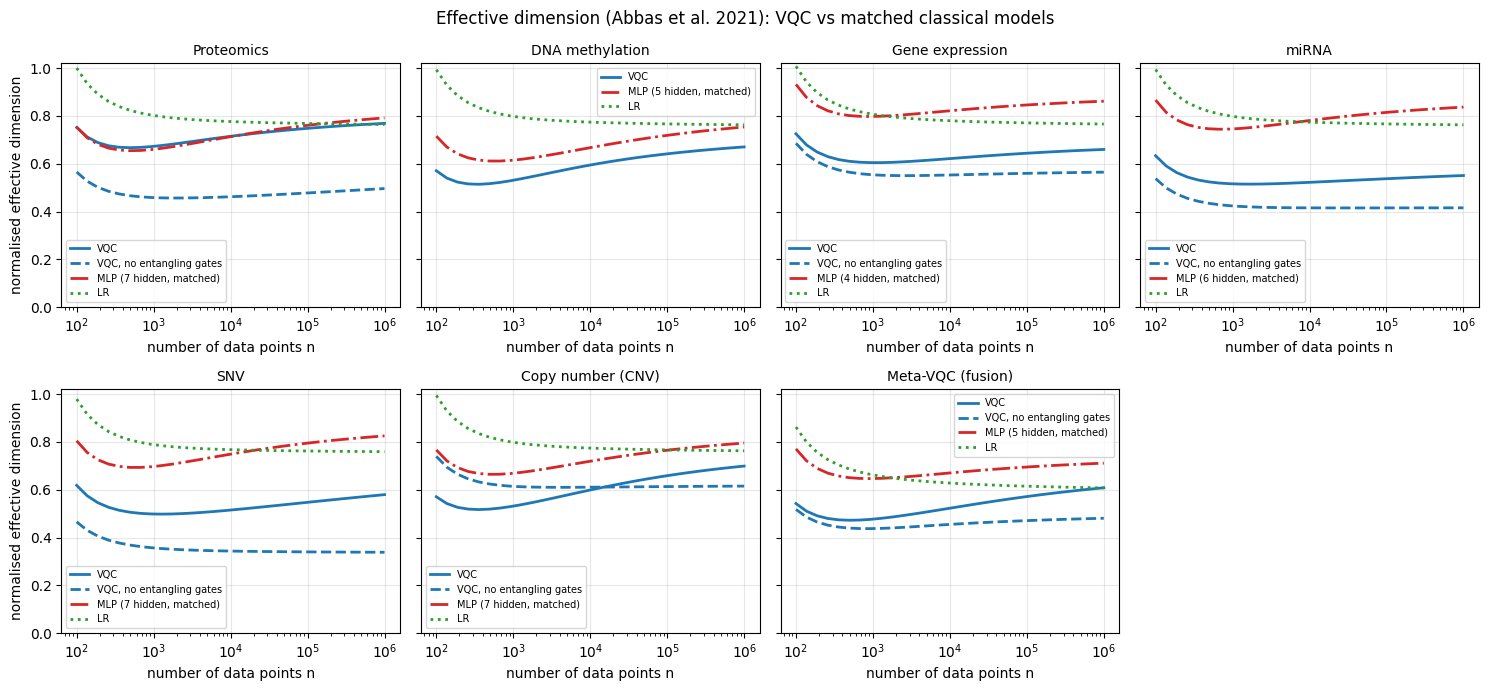

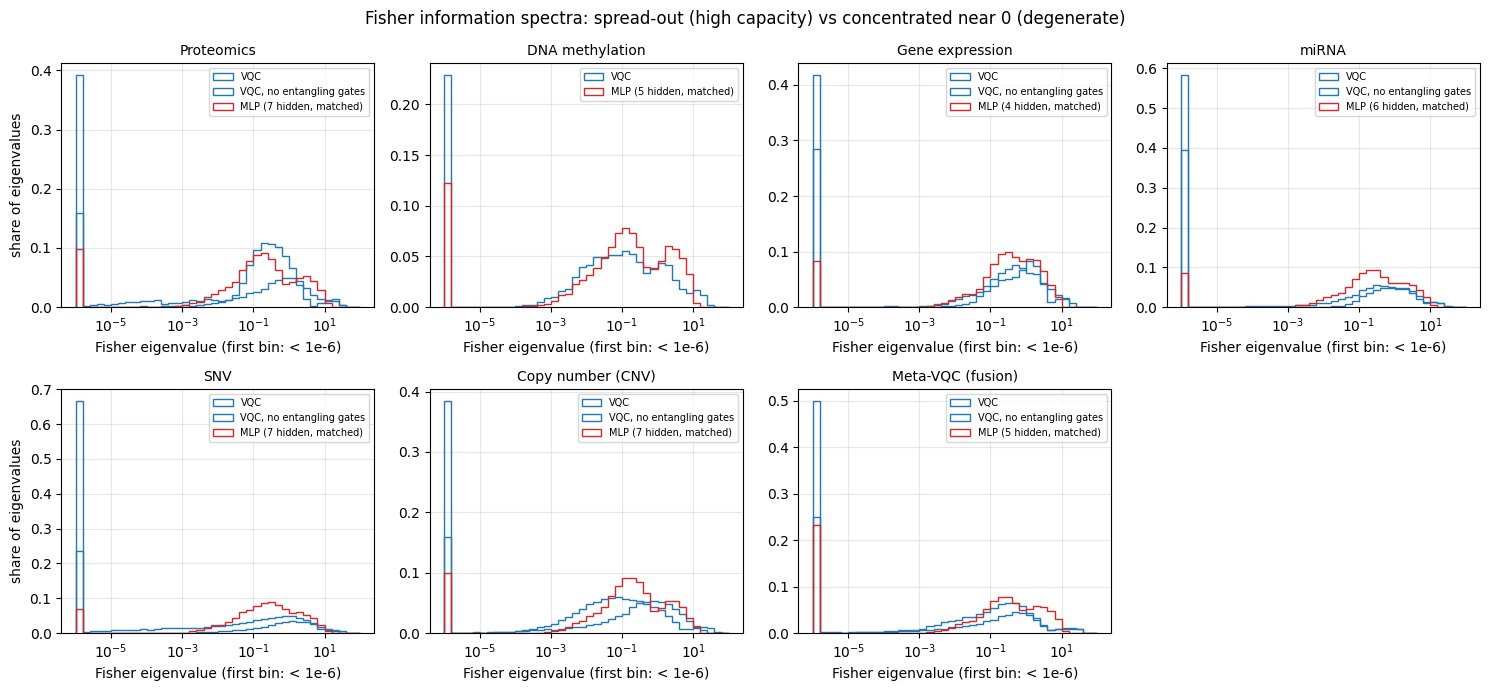

In [7]:
# ============================================================
# 6. FIGURES: effective dimension vs n (D1) and Fisher eigenvalue spectra (D2)
# ============================================================
names = [c.name for c in all_circuits()]
style = lambda lab: dict(VQC=("C0", "-"), LR=("C2", ":")).get(lab, ("C0", "--") if lab.startswith("VQC") else ("C3", "-."))
fig, axs = plt.subplots(2, 4, figsize=(15, 7), sharey=True); axs = axs.ravel()
for ax, nm in zip(axs, names):
    for (n2, lab), v in CURVES.items():
        if n2 == nm:
            col, ls = style(lab); ax.plot(N_GRID, v, color=col, ls=ls, lw=2, label=lab)
    ax.set_xscale("log"); ax.set_title(nm, fontsize=10); ax.set_ylim(0, 1.02); ax.grid(alpha=.3); ax.legend(fontsize=7)
    ax.set_xlabel("number of data points n")
axs[0].set_ylabel("normalised effective dimension"); axs[4].set_ylabel("normalised effective dimension"); axs[-1].axis("off")
fig.suptitle("Effective dimension (Abbas et al. 2021): VQC vs matched classical models"); fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figD1_effective_dimension.png"), dpi=300); plt.show()

fig, axs = plt.subplots(2, 4, figsize=(15, 7)); axs = axs.ravel()
bins = np.logspace(-6, 2, 41)
for ax, nm in zip(axs, names):
    for (n2, lab), ev in SPEC.items():
        if n2 == nm and lab != "LR":
            col, ls = style(lab); e = np.clip(ev.ravel(), 1e-6, None)
            ax.hist(e, bins=bins, weights=np.ones(e.size) / e.size, histtype="step", lw=2, color=col, ls=ls, label=lab)
    ax.set_xscale("log"); ax.set_title(nm, fontsize=10); ax.grid(alpha=.3); ax.legend(fontsize=7)
    ax.set_xlabel("Fisher eigenvalue (first bin: < 1e-6)")
axs[0].set_ylabel("share of eigenvalues"); axs[4].set_ylabel("share of eigenvalues"); axs[-1].axis("off")
fig.suptitle("Fisher information spectra: spread-out (high capacity) vs concentrated near 0 (degenerate)"); fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figD2_fisher_spectrum.png"), dpi=300); plt.show()

In [8]:
# ============================================================
# 7. SUMMARY SENTENCES (check them against the table before using them)
# ============================================================
col = f"norm_eff_dim_n={N_REPORT[-1]:g}"; lines = []
for nm in names:
    sub = D1[D1.circuit == nm].set_index("model"); q = sub.loc["VQC"]
    mlp = sub[sub.index.str.startswith("MLP")].iloc[0]; s = (f"{nm}: VQC ({int(q.parameters)} parameters) normalised effective dimension "
         f"{q[col]:.2f} at n = 10^6 vs {mlp[col]:.2f} for the matched {mlp.name.split(' (')[0]} ({int(mlp.parameters)} parameters) "
         f"and {sub.loc['LR', col]:.2f} for LR ({int(sub.loc['LR', 'parameters'])} parameters)")
    if "VQC, no entangling gates" in sub.index:
        s += f"; without entangling gates {sub.loc['VQC, no entangling gates', col]:.2f}"
    lines.append(s + ".")
txt = "\n".join("• " + l for l in lines) + (
    "\n• Effective dimension measures capacity, not accuracy; compare it with the test F1-scores (Parts A and C) "
    "before drawing any conclusion about quantum vs classical models.")
print(txt); open(os.path.join(OUTPUT_DIR, "D_summary.txt"), "w").write(txt)
print("\nSaved in", OUTPUT_DIR, ":", sorted(os.listdir(OUTPUT_DIR)))

• Proteomics: VQC (82 parameters) normalised effective dimension 0.77 at n = 10^6 vs 0.79 for the matched MLP (81 parameters) and 0.76 for LR (28 parameters); without entangling gates 0.50.
• DNA methylation: VQC (48 parameters) normalised effective dimension 0.67 at n = 10^6 vs 0.75 for the matched MLP (49 parameters) and 0.76 for LR (20 parameters).
• Gene expression: VQC (67 parameters) normalised effective dimension 0.66 at n = 10^6 vs 0.86 for the matched MLP (60 parameters) and 0.77 for LR (40 parameters); without entangling gates 0.56.
• miRNA: VQC (84 parameters) normalised effective dimension 0.55 at n = 10^6 vs 0.84 for the matched MLP (82 parameters) and 0.76 for LR (36 parameters); without entangling gates 0.41.
• SNV: VQC (114 parameters) normalised effective dimension 0.58 at n = 10^6 vs 0.82 for the matched MLP (116 parameters) and 0.76 for LR (48 parameters); without entangling gates 0.34.
• Copy number (CNV): VQC (82 parameters) normalised effective dimension 0.70 at n